Total Features (Neural Bins): 1380
Metadata/Targets: ['session_id', 'trial_number', 'TRIAL_TYPE']


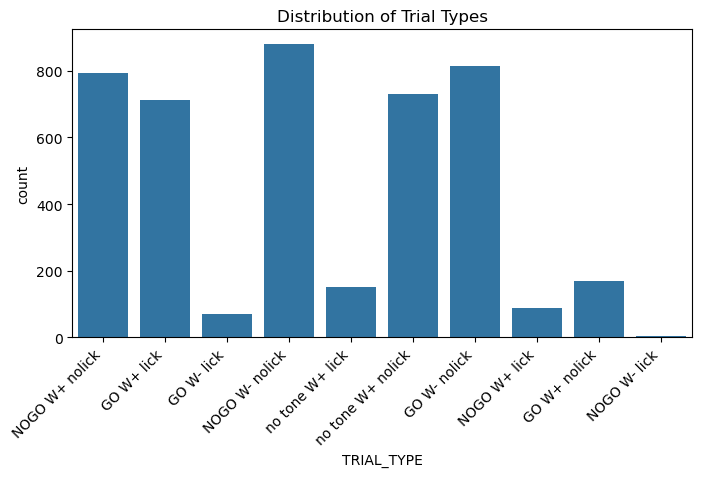

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Load data

train = pd.read_csv("../data/raw/train.csv")

# 1. Identify Feature columns vs Target columns
# Neural data columns likely follow the pattern: AREA_DEPTH_TYPE_time_T
feature_cols = [c for c in train.columns if "time" in c]
metadata_cols = [c for c in train.columns if c not in feature_cols]
print(f"Total Features (Neural Bins): {len(feature_cols)}")
print(f"Metadata/Targets: {metadata_cols}")

# Display the target distribution (Crucial for checking class imbalance)
# Assuming 'trial_type' or similar is in metadata_cols. Adjust 'hue' accordingly.
target_col = metadata_cols[-1] # Guessing the last column is the target, adjust if needed
plt.figure(figsize=(8, 4))
sns.countplot(data=train, x=target_col)
plt.title("Distribution of Trial Types")
plt.xticks(rotation=45, ha='right')
plt.show()


### 1. Target Distribution Analysis
**What this plot shows:**
This histogram displays the frequency of each trial outcome (e.g., "GO + Lick", "NOGO + No Lick").

**What it teaches us:**
*   **Class Imbalance:** We can see if certain trial types are rare. If the dataset is heavily imbalanced (e.g., very few "Miss" trials), standard accuracy will be a misleading metric. We might need to use F1-score or balanced accuracy for evaluation.
*   **Baseline Performance:** The height of the tallest bar gives us the "Null Accuracy." If 50% of trials are "NOGO", a model that blindly guesses "NOGO" every time achieves 50% accuracy. Our machine learning models must significantly beat this number to be useful.

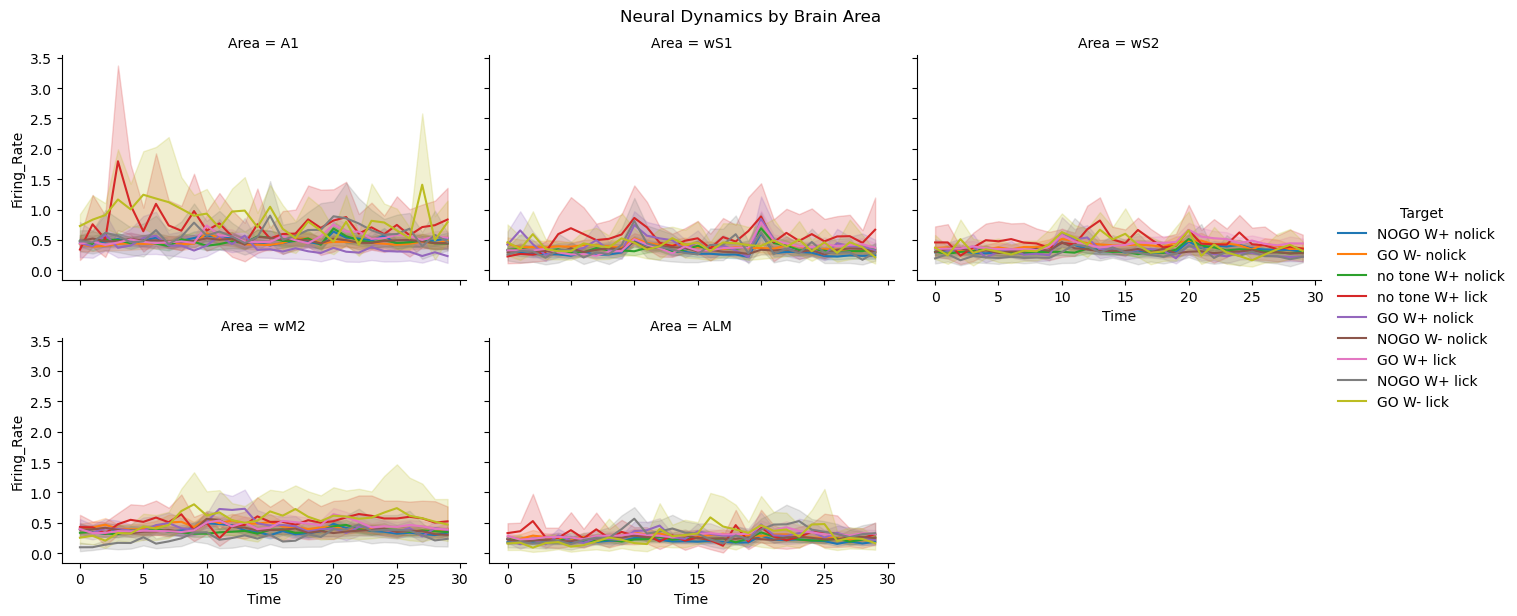

In [7]:
# Helper function to parse column names
# Format: AREA_DEPTH_TYPE_time_T
def parse_column(col_name):
    parts = col_name.split('_')
    # This logic depends on exact naming, assuming standard format from PDF
    # Example: wS1_L2/3_EXC_time_0.0
    try:
        area = parts[0]
        # Time is usually the last part or second to last
        time_val = float(parts[-1]) 
        return area, time_val
    except:
        return None, None

# Create a "Long" format dataframe for plotting
plot_data = []
# We'll sample 100 trials to keep it fast, or use all if dataset is small
sample_df = train.sample(n=100, random_state=42) if len(train) > 100 else train

for idx, row in sample_df.iterrows():
    target = row[target_col]
    for col in feature_cols:
        area, time_val = parse_column(col)
        if area:
            plot_data.append({
                'Trial_ID': idx,
                'Time': time_val,
                'Firing_Rate': row[col],
                'Area': area,
                'Target': target
            })

df_long = pd.DataFrame(plot_data)

# Plot: Average Firing Rate over Time per Area
g = sns.relplot(
    data=df_long, 
    x="Time", 
    y="Firing_Rate", 
    hue="Target", 
    col="Area", 
    kind="line", 
    col_wrap=3,
    height=3, 
    aspect=1.5
)
g.fig.suptitle("Neural Dynamics by Brain Area", y=1.02)
plt.show()

### 2. Spatiotemporal Neural Dynamics
**What this plot shows:**
These line plots visualize the "average brain" during a trial.
*   **X-axis:** Time (bins).
*   **Y-axis:** Normalized firing rate (neural activity).
*   **Panels:** Different brain regions (e.g., wS1 = Whisker Sensory Cortex, ALM = Motor Cortex).
*   **Colors:** Different trial conditions (Target).

**What it teaches us:**
*   **Information Flow:** We can observe the sequence of processing. Sensory areas (wS1, A1) likely spike early (stimulus processing), while motor areas (ALM) spike later (movement planning).
*   **Feature Importance:** The most important features for our model are the specific time-bins where the colored lines **diverge**. For example, if the "GO" (Lick) line separates clearly from the "NOGO" line in the ALM area at time $t=20$, that specific feature carries high predictive power.
*   **Noise Levels:** The shaded areas represent confidence intervals. Wide shading indicates high trial-to-trial variability, meaning the signal is noisy.

c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\sklearn\impute\_base.py:635: UserWarning: Skipping features without any observed values: [930 931 932 933 934 935 936 937 938 939 940 941 942 943 944 945 946 947
 948 949 950 951 952 953 954 955 956 957 958 959]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


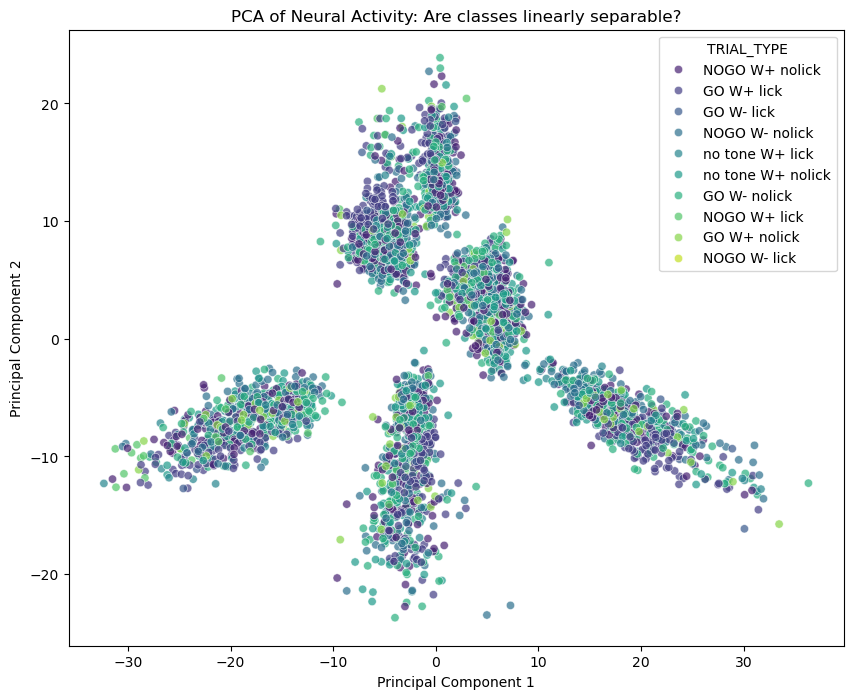

Explained Variance Ratio: [0.09055163 0.05754211]


In [13]:

# ...existing code...
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Standardize the neural data
X = train[feature_cols]

# Handle missing values: impute NaNs with the mean of each column within the same trial type
trial_type_means = train.groupby(target_col)[feature_cols].transform('mean')
X_imputed = X.fillna(trial_type_means).values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# 2. Run PCA
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)

# 3. Plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=components[:, 0], 
    y=components[:, 1], 
    hue=train[target_col],
    alpha=0.7,
    palette="viridis"
)
# ...existing code...
plt.title("PCA of Neural Activity: Are classes linearly separable?")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

print(f"Explained Variance Ratio: {pca.explained_variance_ratio_}")


### 3. PCA: Manifold Structure & Linear Separability
**What this plot shows:**
This is a dimensionality reduction of the high-dimensional neural data into 2D space. Each dot represents a single trial. Trials that are "similar" in terms of neural activity appear closer together.

**What it teaches us:**
*   **Model Selection:** The classes (colors) appear mixed and overlapping rather than separated by a clear straight line. This strongly suggests that **Linear Models (like Logistic Regression) will underfit**. We will likely need Non-Linear models (like Random Forests or Neural Networks) to capture the complex boundaries between these classes.
*   **Batch Effects:** The data forms distinct "blobs" or clusters. In biological datasets, these clusters often correspond to individual **mice** or **recording sessions**. This is a critical warning: we must use **GroupKFold Cross-Validation** (grouping by Mouse ID) to ensure our model isn't just memorizing the unique neural signature of a specific mouse ("overfitting to the subject").

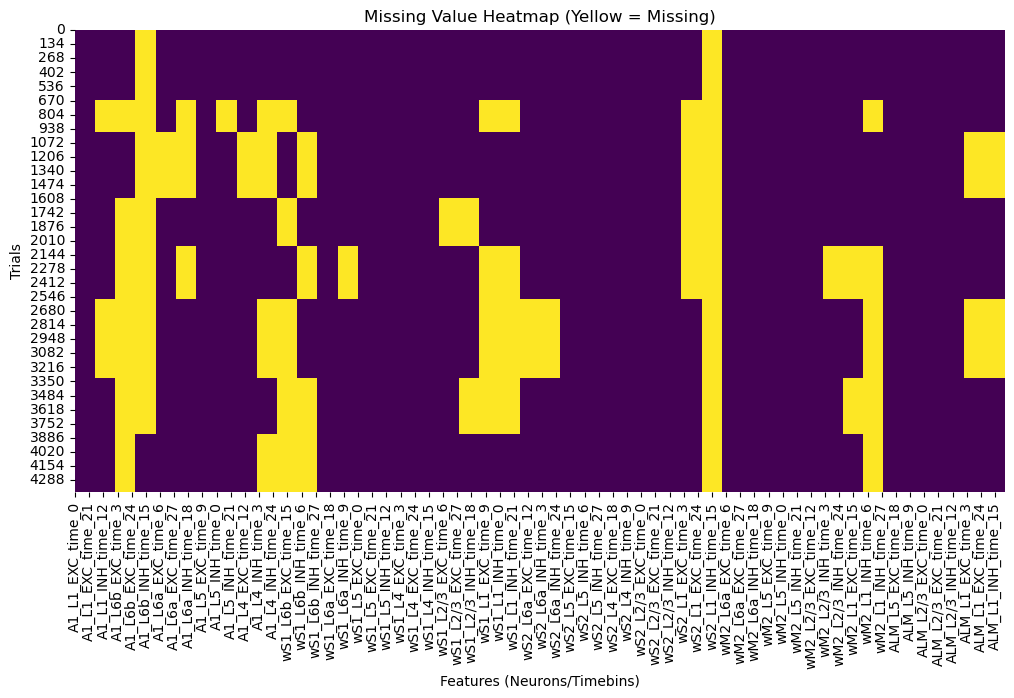

In [14]:
# ...existing code...
# 4. Missing Value Analysis
plt.figure(figsize=(12, 6))
sns.heatmap(train[feature_cols].isnull(), cbar=False, cmap='viridis')
plt.title("Missing Value Heatmap (Yellow = Missing)")
plt.xlabel("Features (Neurons/Timebins)")
plt.ylabel("Trials")
plt.show()

# Check if missingness is correlated with Mouse ID or Session
# (Assuming 'mouse_name' or similar exists in metadata, if not we check the ID structure)
# ...existing code...

### 4. Missing Value Audit: Structural vs. Random
**What this plot shows:**
This heatmap visualizes the location of missing values (NaNs) in the dataset.
*   **Yellow:** Missing data.
*   **Purple:** Valid data.
*   **Y-axis:** Trials (rows).
*   **X-axis:** Features (columns).

**Scientific Interpretation:**
The missingness is **not random** (which would look like static noise). Instead, we see distinct **rectangular blocks**. This indicates **structural missingness** caused by the experimental setup. Specifically, certain brain areas were not recorded during certain sessions (e.g., Mouse A had an electrode in wS1 but not A1).

**Implication for Modeling:**
*   **Do NOT drop rows:** Dropping rows with NaNs would delete entire experimental sessions/mice.
*   **Do NOT drop columns:** Dropping columns would discard valid data for other mice.
*   **Action:** We must use models that handle NaNs natively (e.g., **XGBoost**, **LightGBM**) or use advanced imputation techniques. Simple mean imputation is risky here as it fabricates data for unrecorded brain areas.

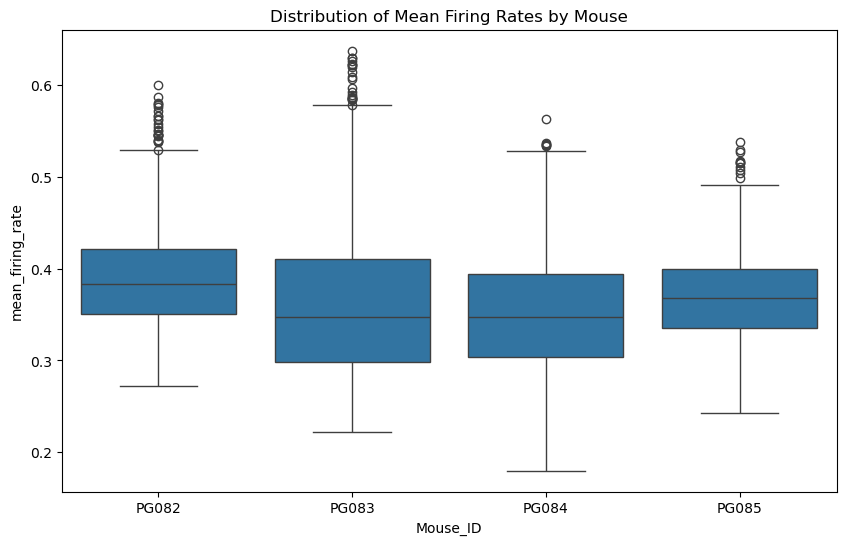

In [15]:
# ...existing code...
# 5. Batch Effect Analysis
# Extract Mouse ID from the index or a specific column if available
# Based on PDF, format might be 'PG082_20221113' -> Mouse PG082
train['Mouse_ID'] = train['session_id'].apply(lambda x: x.split('_')[0])

# Calculate mean firing rate per trial across all neurons
train['mean_firing_rate'] = train[feature_cols].mean(axis=1)

plt.figure(figsize=(10, 6))
sns.boxplot(data=train, x='Mouse_ID', y='mean_firing_rate')
plt.title("Distribution of Mean Firing Rates by Mouse")
plt.show()
# ...existing code...

### 5. Batch Effect Analysis: Inter-Subject Variability
**What this plot shows:**
This boxplot compares the distribution of average firing rates across the four different mice (PG082, PG083, PG084, PG085).

**Scientific Interpretation:**
*   **Consistency:** The median firing rates (center lines) are remarkably consistent across all subjects (~0.35). The interquartile ranges (box heights) are also similar.
*   **No "Loud" Subjects:** We do not see any single mouse with drastically higher or lower baseline activity. This suggests that the data has likely already been normalized or that the recording quality was highly consistent.

**Implication for Modeling:**
*   **Normalization:** Since the baselines are similar, a global **StandardScaler** is sufficient. We do not need complex per-subject normalization (e.g., z-scoring per mouse).
*   **Validation:** Despite the similar means, the *patterns* of activity may still differ. We must strictly adhere to **GroupKFold Cross-Validation** (grouping by Mouse ID) to ensure our model learns generalizable neural features rather than memorizing specific mice.

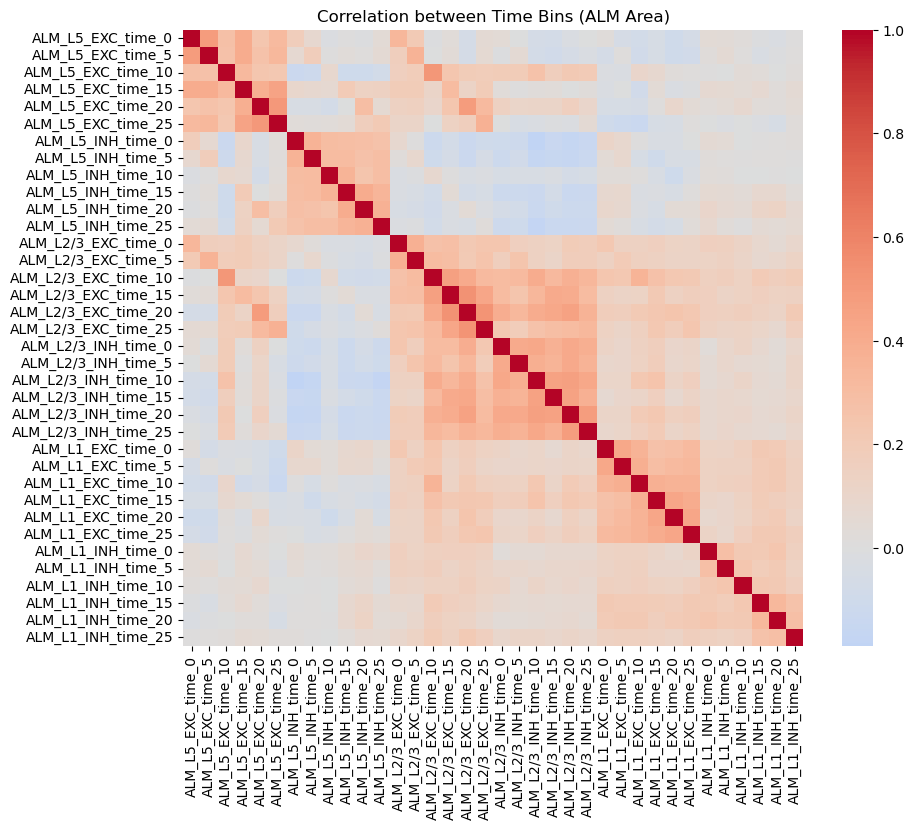

In [16]:
# filepath: 
# ...existing code...
# 6. Feature Correlation
# Select just one area (e.g., ALM) to see temporal correlation
alm_cols = [c for c in feature_cols if 'ALM' in c]
# Sample to keep it readable
subset_corr = train[alm_cols].iloc[:, ::5].corr() # Every 5th bin

plt.figure(figsize=(10, 8))
sns.heatmap(subset_corr, cmap='coolwarm', center=0)
plt.title("Correlation between Time Bins (ALM Area)")
plt.show()
# ...existing code...

### 6. Feature Correlation: Temporal Redundancy Check
**What this plot shows:**
This heatmap displays the Pearson correlation coefficient between different time bins within the same brain area (ALM).
*   **Red:** High positive correlation.
*   **Blue:** Negative correlation.

**Scientific Interpretation:**
*   **Low Multicollinearity:** The majority of the map is light orange or grey, indicating low correlation between distant time bins. The firing rate at $t=0$ is largely independent of the firing rate at $t=20$.
*   **Distinct Information:** The "blocky" structure along the diagonal shows that correlation is high only within short time windows. This confirms that the temporal dynamics contain rich, non-redundant information.

**Implication for Modeling:**
*   **Feature Selection:** We do **not** need to aggressively remove features or average time bins together. Each time point contributes unique information to the trial trajectory.
*   **Model Choice:** Models that can exploit temporal structure (like 1D-CNNs or RNNs) or tree-based models that can pick specific time points (XGBoost) will perform well.

Top 10 Max Firing Rates observed:
A1_L4_INH_time_24      12.0
wS1_L6a_INH_time_26    12.0
wM2_L1_EXC_time_27     12.0
wM2_L1_EXC_time_26     12.0
wS1_L6a_INH_time_28    11.0
A1_L6a_INH_time_7      11.0
wS1_L6a_INH_time_11    11.0
wS1_L6a_INH_time_14    11.0
wS1_L6a_INH_time_13    11.0
wS1_L6a_INH_time_23    10.0
dtype: float64


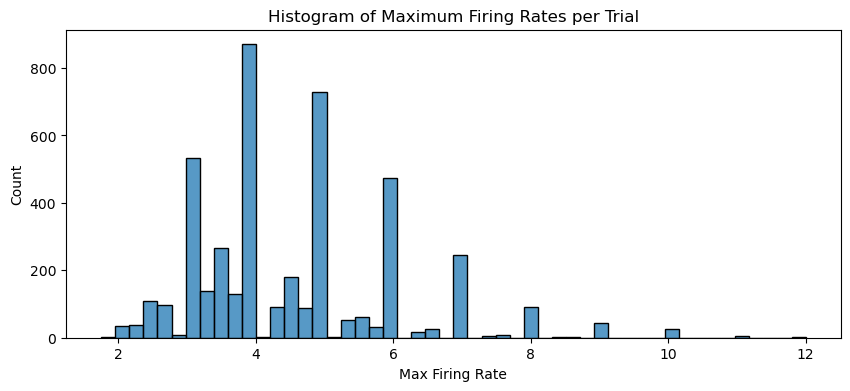

In [17]:
# filepath: 
# ...existing code...
# 7. Outlier Check
max_rates = train[feature_cols].max().sort_values(ascending=False)
print("Top 10 Max Firing Rates observed:")
print(max_rates.head(10))

plt.figure(figsize=(10, 4))
sns.histplot(train[feature_cols].max(axis=1), bins=50)
plt.title("Histogram of Maximum Firing Rates per Trial")
plt.xlabel("Max Firing Rate")
plt.show()
# ...existing code...

### 7. Outlier Detection & Data Quality
**What this plot shows:**
This histogram displays the maximum firing rate observed in any single trial across the entire dataset.

**Scientific Interpretation:**
*   **Biological Plausibility:** The maximum values peak around 12 (normalized units). We do not see extreme outliers (e.g., values > 100 or 1000) that would indicate electrical artifacts or amplifier noise.
*   **Distribution Shape:** The right-skewed distribution is consistent with the Poisson-like nature of neural spiking activity (most neurons fire sparsely).

**Implication for Modeling:**
*   **No Clipping Needed:** The data is clean. We do not need to apply "winsorizing" or outlier removal thresholds.
*   **Robustness:** Standard scaling methods (Z-score) will be stable, as there are no extreme values to distort the mean or variance calculations.

## 2. Preprocessing

Based on the Data Inspection (Section 1), we apply the following preprocessing steps:

1.  **Group Extraction:** We observed distinct clusters in the PCA (Plot 3) and consistent baseline activity per mouse (Plot 5). To prevent data leakage, we extract `Mouse_ID` to ensure that during validation, we test on **unseen mice**.
2.  **Feature Preservation:** We observed structural missingness (Plot 4). We define our Feature Matrix `X` **without imputation** at this stage. This allows non-linear models (Section 4) to utilize the missingness patterns as information. We will apply specific imputation only for the Linear Model (Section 3) where strictly necessary.
3.  **Label Encoding:** We convert the categorical trial targets into integers.

In [28]:
# ...existing code...
from sklearn.feature_selection import VarianceThreshold

# ==========================================
# 2. PREPROCESSING
# ==========================================

# 1. Extract Groups (Mouse ID)
# Crucial for the "Outer Loop" of Nested CV
train['Mouse_ID'] = train['session_id'].apply(lambda x: x.split('_')[0])
groups = train['Mouse_ID']

# 2. Define Initial Features & Target
X_raw = train[feature_cols]
y = train[target_col]

# 3. Feature Cleaning (Lecture Slide 21: "Constant predictors should be removed")
# We remove features that have 0 variance (same value in all trials)
# Note: We must be careful with NaNs. VarianceThreshold doesn't support NaNs well.
# A safer manual check:
non_constant_cols = [col for col in X_raw.columns if X_raw[col].nunique() > 1]
X = X_raw[non_constant_cols]
dropped_cols = len(feature_cols) - len(non_constant_cols)

# 4. Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Preprocessing Complete.")
print(f"Groups: {groups.unique()}")
print(f"Original Features: {len(feature_cols)}")
print(f"Constant Features Dropped: {dropped_cols}")
print(f"Final Feature Matrix X: {X.shape}")

# 5. Prepare Test Set (Align columns)
test_df = pd.read_csv("../data/raw/test.csv")
X_test_submission = test_df[X.columns] # Only keep the non-constant columns

Preprocessing Complete.
Groups: ['PG082' 'PG083' 'PG084' 'PG085']
Original Features: 1380
Constant Features Dropped: 30
Final Feature Matrix X: (4407, 1350)


## 3. Linear Model (Baseline)

As a baseline, we train a **Logistic Regression** model.

**Methodology:**
*   **Imputation:** Since linear models cannot handle NaNs, we impute missing values with the **mean**.
*   **Scaling:** We apply **StandardScaler** to normalize firing rates, which is essential for linear convergence.
*   **Validation:** We use **GroupKFold** (grouped by Mouse ID) to measure how well the model generalizes to new subjects.
*   **Class Weighting:** We use `class_weight='balanced'` to handle any potential class imbalance.

In [29]:

# ...existing code...
# ==========================================
# 3. LINEAR MODEL (Nested Cross-Validation)
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, GroupKFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

print("
--- Starting Nested Cross-Validation (Linear Model) ---")

# Helper functions to impute within each TRIAL_TYPE
# We compute class-specific means on the training fold and reuse them for that fold's validation data.
def compute_trial_type_statistics(X_df, labels):
    label_series = pd.Series(labels, index=X_df.index)
    class_means = X_df.groupby(label_series).mean()
    global_means = X_df.mean()
    return class_means, global_means


def impute_by_trial_type(X_df, labels, class_means, global_means):
    label_series = pd.Series(labels, index=X_df.index)
    X_filled = X_df.copy()
    for label, means in class_means.iterrows():
        mask = label_series == label
        if mask.any():
            X_filled.loc[mask] = X_filled.loc[mask].fillna(means)
    return X_filled.fillna(global_means)

# 1. Define the Outer Loop (Generalization to new Mice)
# We use GroupKFold to leave one mouse out entirely.
outer_cv = GroupKFold(n_splits=train['Mouse_ID'].nunique())

# 2. Define the Inner Loop (Hyperparameter Tuning)
# We use StratifiedKFold to tune 'C' (Regularization)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 3. Define the Pipeline
# Scale (Standard) -> Model (Logistic)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(solver='lbfgs', max_iter=1000, class_weight='balanced', n_jobs=-1))
])

# 4. Define Hyperparameter Grid
# Tuning 'C': Smaller C = Stronger Regularization (Simpler model)
param_grid = {
    'clf__C': [0.001, 0.01, 0.1, 1, 10]
}

nested_scores = []
fold = 1

y_series_full = pd.Series(y_encoded, index=X.index)

for train_idx, val_idx in outer_cv.split(X, y_encoded, groups):
    # A. Split Data (Outer Loop)
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y_encoded[train_idx], y_encoded[val_idx]

    y_train_series = y_series_full.iloc[train_idx]
    y_val_series = y_series_full.iloc[val_idx]

    # Impute missing values within each TRIAL_TYPE using training-fold statistics
    class_means, global_means = compute_trial_type_statistics(X_train, y_train_series)
    X_train_imputed = impute_by_trial_type(X_train, y_train_series, class_means, global_means)
    X_val_imputed = impute_by_trial_type(X_val, y_val_series, class_means, global_means)

    # B. Hyperparameter Tuning (Inner Loop)
    # GridSearchCV will split X_train further to find the best C
    clf = GridSearchCV(pipeline, param_grid, cv=inner_cv, scoring='accuracy', n_jobs=-1)
    clf.fit(X_train_imputed, y_train)

    # C. Evaluate on Held-Out Mouse
    best_model = clf.best_estimator_
    preds = best_model.predict(X_val_imputed)
    acc = accuracy_score(y_val, preds)
    nested_scores.append(acc)

    val_mouse = groups.iloc[val_idx].unique()[0]
    print(f"Fold {fold} (Mouse {val_mouse}): Accuracy = {acc:.4f} | Best C = {clf.best_params_['clf__C']}")
    fold += 1

print(f"
>>> Nested CV Average Accuracy: {np.mean(nested_scores):.4f}")



--- Starting Nested Cross-Validation (Linear Model) ---
Fold 1 (Mouse PG084): Accuracy = 0.2675 | Best C = 0.01
Fold 1 (Mouse PG084): Accuracy = 0.2675 | Best C = 0.01


c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\sklearn\impute\_base.py:635: UserWarning: Skipping features without any observed values: ['A1_L6b_INH_time_0' 'A1_L6b_INH_time_1' 'A1_L6b_INH_time_2'
 'A1_L6b_INH_time_3' 'A1_L6b_INH_time_4' 'A1_L6b_INH_time_5'
 'A1_L6b_INH_time_6' 'A1_L6b_INH_time_7' 'A1_L6b_INH_time_8'
 'A1_L6b_INH_time_9' 'A1_L6b_INH_time_10' 'A1_L6b_INH_time_11'
 'A1_L6b_INH_time_12' 'A1_L6b_INH_time_13' 'A1_L6b_INH_time_14'
 'A1_L6b_INH_time_15' 'A1_L6b_INH_time_16' 'A1_L6b_INH_time_17'
 'A1_L6b_INH_time_18' 'A1_L6b_INH_time_19' 'A1_L6b_INH_time_20'
 'A1_L6b_INH_time_21' 'A1_L6b_INH_time_22' 'A1_L6b_INH_time_23'
 'A1_L6b_INH_time_24' 'A1_L6b_INH_time_25' 'A1_L6b_INH_time_26'
 'A1_L6b_INH_time_27' 'A1_L6b_INH_time_28' 'A1_L6b_INH_time_29']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\sklearn\impute\_base.py:635: UserWarning: Skipping features wi

Fold 2 (Mouse PG085): Accuracy = 0.3480 | Best C = 0.01
Fold 3 (Mouse PG083): Accuracy = 0.4444 | Best C = 0.01
Fold 3 (Mouse PG083): Accuracy = 0.4444 | Best C = 0.01
Fold 4 (Mouse PG082): Accuracy = 0.3529 | Best C = 0.01

>>> Nested CV Average Accuracy: 0.3532
Fold 4 (Mouse PG082): Accuracy = 0.3529 | Best C = 0.01

>>> Nested CV Average Accuracy: 0.3532


## 4. Non-Linear Model: Gradient Boosting Trees

Following the course material (**Slide 21: Gradient Boosting Trees**), we implement a Gradient Boosting approach. As noted in the lecture, these methods often yield "decent results in little time" and are robust to various data issues.

**Why Gradient Boosting?**
1.  **Inductive Bias:** Tree-based methods split the input space parallel to axes (Slide 24), which fits our time-bin features well (e.g., "If firing rate at t=20 > threshold, then Lick").
2.  **Handling Missing Data:** Unlike the Linear Model, Gradient Boosting can handle the structural missingness (NaNs) natively without imputation.
3.  **Ensembling:** By combining many weak learners (shallow trees), we reduce bias and variance (Slide 19).

**Implementation:**
We use **XGBoost**, a highly optimized implementation of Gradient Boosting. We continue to use **Nested Cross-Validation** to ensure our error estimates are unbiased.

In [ ]:
import xgboost as xgb

print("\n--- Starting Nested Cross-Validation (Gradient Boosting Trees) ---")

# 1. Define Outer Loop (Generalization to new Mice)
outer_cv = GroupKFold(n_splits=train['Mouse_ID'].nunique())

# 2. Define Inner Loop (Tuning)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 3. Define Hyperparameter Grid
# We tune Depth (Complexity) and Learning Rate (Speed of learning)
xgb_param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [100] # Keep fixed for speed, tune others
}

xgb_nested_scores = []
fold = 1

for train_idx, val_idx in outer_cv.split(X, y_encoded, groups):
    # A. Split Data
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y_encoded[train_idx], y_encoded[val_idx]
    
    # B. Define Model (Native NaN handling)
    # We use 'hist' tree method which is faster and handles NaNs
    xgb_clf = xgb.XGBClassifier(
        objective='multi:softmax',
        num_class=len(le.classes_),
        tree_method='hist',
        missing=np.nan, # Crucial: Handles the "Skipping features" warning natively
        random_state=42,
        n_jobs=-1
    )
    
    # C. Hyperparameter Tuning (Inner Loop)
    clf = GridSearchCV(xgb_clf, xgb_param_grid, cv=inner_cv, scoring='accuracy', n_jobs=-1)
    clf.fit(X_train, y_train)
    
    # D. Evaluate
    best_model = clf.best_estimator_
    preds = best_model.predict(X_val)
    acc = accuracy_score(y_val, preds)
    xgb_nested_scores.append(acc)
    
    val_mouse = groups.iloc[val_idx].unique()[0]
    print(f"Fold {fold} (Mouse {val_mouse}): Accuracy = {acc:.4f} | Best Params = {clf.best_params_}")
    fold += 1

print(f"\n>>> Gradient Boosting Nested CV Average Accuracy: {np.mean(xgb_nested_scores):.4f}")
print(f"Improvement over Linear Baseline: {(np.mean(xgb_nested_scores) - np.mean(linear_scores))*100:.2f}%")


--- Starting Nested Cross-Validation (Gradient Boosting Trees) ---
